# ProteinStruct-ML — Exploratory Data Analysis (EDA)

 ## Objectives
- Investigate the distribution of RMSD.
- Explore the distributions of physicochemical descriptors F1–F9.
- Identify potential outliers and relationships between variables.
- Examine correlations between predictors and RMSD.
- Generate insights to guide machine learning model development.

## Inputs
- data/processed/casp_cleaned.csv

## Outputs
- Exploratory visualizations
- Statistical observations
- Insights for feature engineering and model selection



---

# Change working directory

* We are assuming you will store the notebooks in a subfolder, therefore when running the notebook in the editor, you will need to change the working directory

We need to change the working directory from its current folder to its parent folder
* We access the current directory with os.getcwd()

In [1]:
import os
from pathlib import Path

current_dir = Path.cwd()
print("Current directory:", current_dir)

Current directory: c:\Users\trasn\OneDrive\Dokumente\programing\ML fundamentals\Capstone\ProteinStruct-ML\jupyter_notebooks


We want to make the parent of the current directory the new current directory
* os.path.dirname() gets the parent directory
* os.chir() defines the new current directory

In [2]:
if Path.cwd().name == "jupyter_notebooks":
    os.chdir(Path.cwd().parent)

print("Working directory set to:", Path.cwd())

Working directory set to: c:\Users\trasn\OneDrive\Dokumente\programing\ML fundamentals\Capstone\ProteinStruct-ML


Confirm the new current directory

In [3]:
print("Confirmed project directory:", Path.cwd())

Confirmed project directory: c:\Users\trasn\OneDrive\Dokumente\programing\ML fundamentals\Capstone\ProteinStruct-ML


## Section 1 — Load Cleaned Dataset

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/processed/casp_cleaned.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (44019, 10)


,RMSD,F1,F2,F3,F4,F5,F6,F7,F8,F9
0,17.284,13558.30,4305.35,0.31754,162.1730,1.872791e+06,215.3590,4287.87,102,27.0302
1,6.021,6191.96,1623.16,0.26213,53.3894,8.034467e+05,87.2024,3328.91,39,38.5468
2,9.275,7725.98,1726.28,0.22343,67.2887,1.075648e+06,81.7913,2981.04,29,38.8119
3,15.851,8424.58,2368.25,0.28111,67.8325,1.210472e+06,109.4390,3248.22,70,39.0651
4,7.962,7460.84,1736.94,0.23280,52.4123,1.021020e+06,94.5234,2814.42,41,39.9147


## Section 2 — Target Variable Analysis

### Distribution of RMSD

The objective is to investigate the distribution of RMSD,
identify potential skewness, and understand the range of
structural deviations in the dataset.

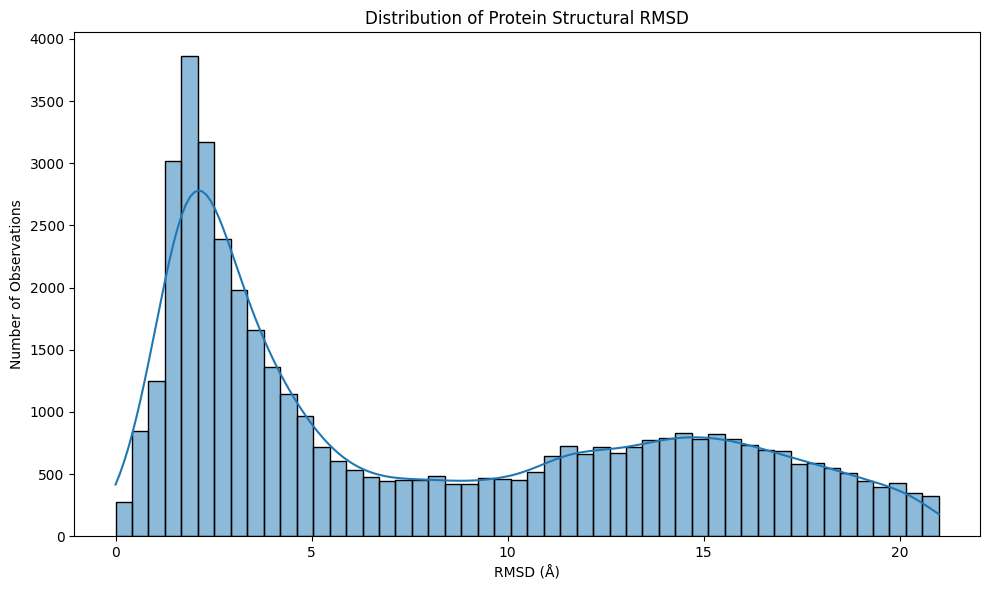

In [15]:
# Visualize the distribution of RMSD
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="RMSD",
    bins=50,
    kde=True
)

plt.title("Distribution of Protein Structural RMSD")
plt.xlabel("RMSD (Å)")
plt.ylabel("Number of Observations")

plt.tight_layout()

plt.savefig(
    "images/rmsd_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### RMSD Distribution — Findings

The RMSD histogram reveals a non-normal, apparently bimodal
distribution.

Two main concentrations of observations are visible:

- A prominent peak around 1.5–3 Å, representing protein models
  with relatively low structural deviation.
- A broader peak around 14–16 Å, representing models with
  substantially higher structural deviation.

The distribution contains fewer observations in the
intermediate RMSD range, approximately 7–10 Å.

This suggests that the dataset contains distinct regions
of structural deviation, although the underlying cause
cannot be established from the histogram alone.

**Implications for machine learning:**

- A single global error metric may conceal differences in
  predictive performance across RMSD ranges.
- Model evaluation should include MAE, RMSE, and R².
- Prediction errors may also be examined across low- and
  high-RMSD observations.

The target distribution will be preserved for regression.
No target transformation is applied at this stage.

In [6]:
# Calculate RMSD distribution statistics
print(f"Mean RMSD: {df['RMSD'].mean():.3f}")
print(f"Median RMSD: {df['RMSD'].median():.3f}")
print(f"Skewness: {df['RMSD'].skew():.3f}")
print(f"Kurtosis: {df['RMSD'].kurt():.3f}")

Mean RMSD: 7.796
Median RMSD: 5.087
Skewness: 0.553
Kurtosis: -1.162


### RMSD Distribution — Statistical Interpretation

The cleaned dataset has the following RMSD statistics:

- Mean: 7.796 Å
- Median: 5.087 Å
- Skewness: 0.553
- Excess kurtosis: -1.162

The positive skewness indicates moderate right-sided
asymmetry, consistent with the mean exceeding the median.

The negative excess kurtosis indicates a distribution with
lower kurtosis than a normal distribution.

Together with the histogram, these results indicate a
non-normal distribution with two apparent peaks.

**Machine Learning Implications**

The uneven target distribution may affect model performance
across different RMSD ranges.

In addition to overall MAE, RMSE, and R², prediction errors
will be examined across different RMSD intervals.

No target transformation will be applied at this stage.


### Statistical Principles and Their Application

Statistical analysis helps describe the distribution of protein
structural deviations and identify patterns in the dataset.

The following statistical concepts are relevant to this project:

- **Mean:** The arithmetic average of observed values. For RMSD,
  it describes the average structural deviation across observations.

- **Median:** The middle value of an ordered dataset. It is less
  sensitive to extreme values than the mean.

- **Standard deviation:** Measures the spread of observations
  around their mean. A larger standard deviation indicates
  greater variability in RMSD.

- **Variance:** The square of the standard deviation, representing
  variability in squared units.

- **Skewness:** Describes the asymmetry of a distribution.
  Positive skewness indicates a longer right-hand tail.

- **Probability:** Describes how likely an event is to occur.
  In this dataset, empirical probabilities can be estimated
  from the proportion of observations satisfying a condition,
  such as RMSD below a specified threshold.

- **Hypothesis testing:** A statistical method used to evaluate
  evidence against a null hypothesis. It helps determine whether
  an observed association is statistically distinguishable
  from zero under specified assumptions.

These principles support the exploratory analysis and help
guide the selection and evaluation of machine learning models.


In [7]:
# Descriptive statistics for RMSD
rmsd = df["RMSD"]

print("RMSD Descriptive Statistics")
print(f"Mean:               {rmsd.mean():.3f} Å")
print(f"Median:             {rmsd.median():.3f} Å")
print(f"Standard deviation: {rmsd.std():.3f} Å")
print(f"Variance:           {rmsd.var():.3f} Å²")
print(f"Skewness:           {rmsd.skew():.3f}")

# Empirical probability of observing RMSD below 5 Å
prob_below_5 = (rmsd < 5).mean()

print(f"\nP(RMSD < 5 Å): {prob_below_5:.3f}")
print(f"Percentage:    {prob_below_5 * 100:.1f}%")

RMSD Descriptive Statistics
Mean:               7.796 Å
Median:             5.087 Å
Standard deviation: 6.138 Å
Variance:           37.673 Å²
Skewness:           0.553

P(RMSD < 5 Å): 0.496
Percentage:    49.6%


### Interpretation of Descriptive Statistics

The cleaned CASP dataset has a mean RMSD of 7.796 Å and
a median of 5.087 Å.

The mean is higher than the median, indicating that larger
RMSD observations influence the average. This is consistent
with the positive skewness of 0.553, suggesting a moderately
right-skewed distribution.

The standard deviation of 6.138 Å and variance of
37.673 Å² indicate substantial variability in structural
deviation across the dataset.

The empirical probability of observing RMSD below 5 Å
is 0.496 (49.6%). Therefore, approximately half of the
observations have RMSD values below this threshold.

This probability represents the observed proportion in the
cleaned dataset, rather than a prediction for a new protein.

These findings demonstrate the application of descriptive
statistics and empirical probability to protein structural
data and provide context for subsequent machine learning
analysis.


## Section 2 — Target Variable Analysis

### Distribution of RMSD

The objective is to investigate the distribution of RMSD,
identify potential skewness, and understand the range of
structural deviations in the dataset.

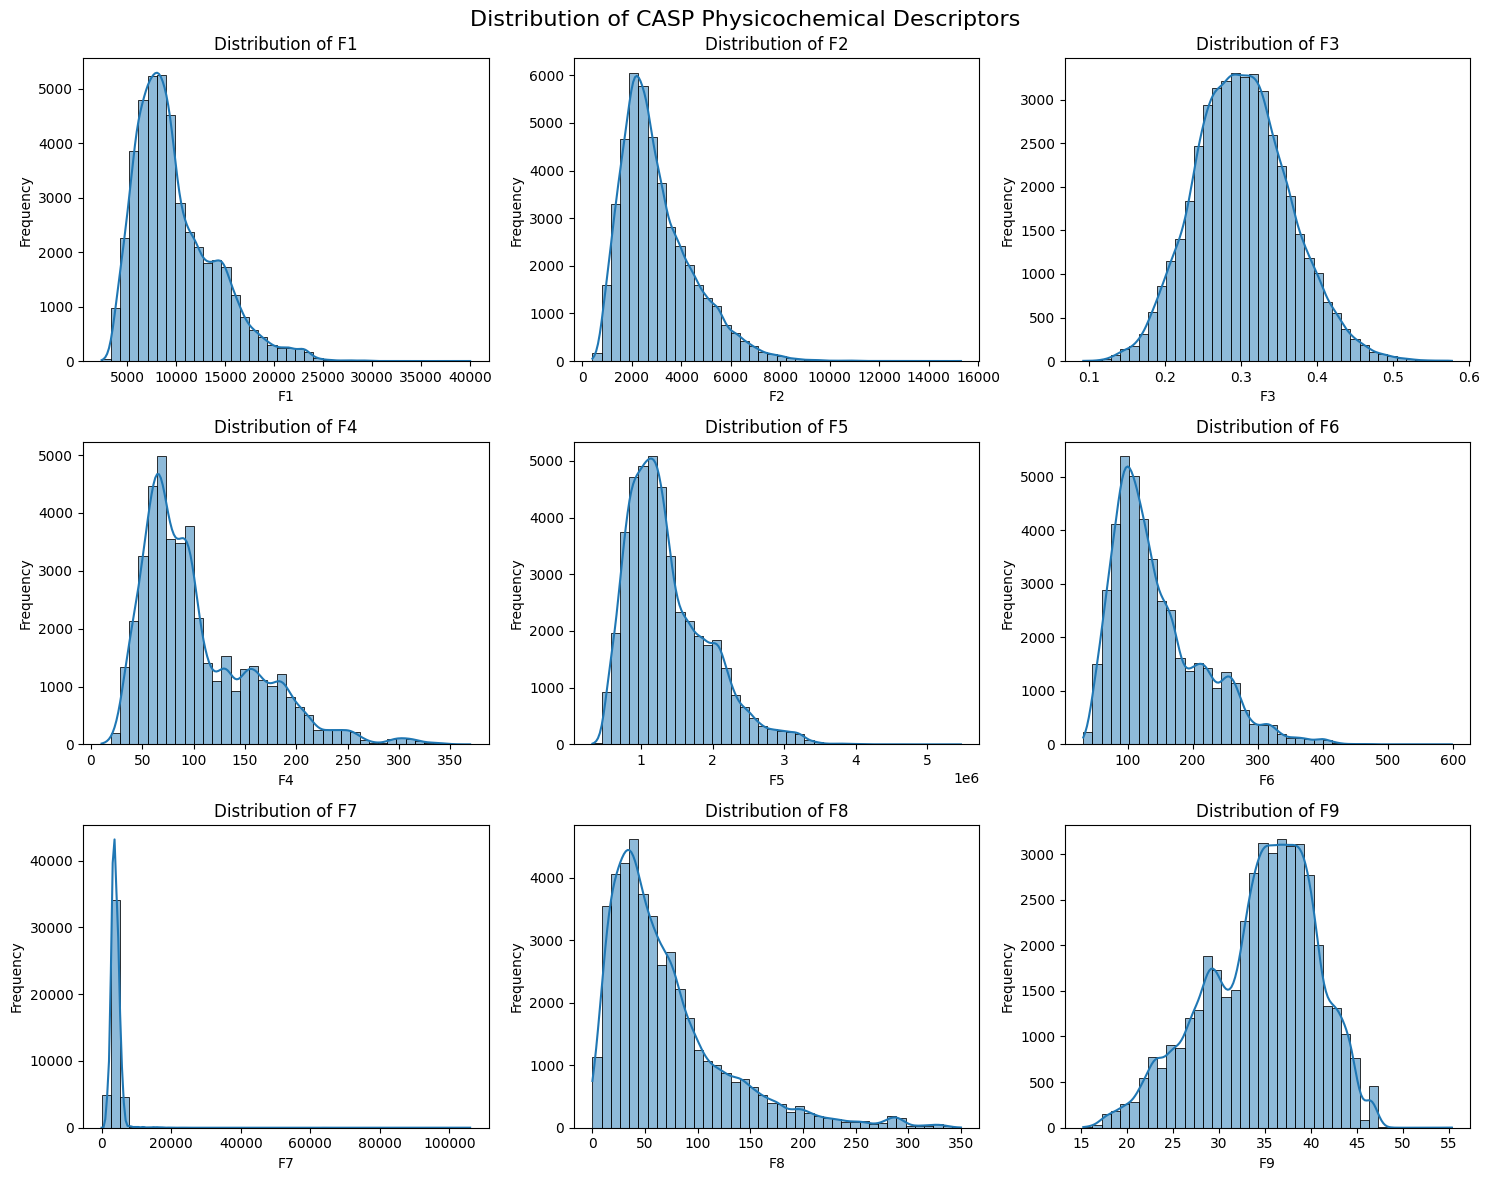

In [14]:
# Select the nine predictor variables
feature_columns = [f"F{i}" for i in range(1, 10)]

# Create histograms for all predictors
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for ax, feature in zip(axes.flatten(), feature_columns):
    sns.histplot(
        data=df,
        x=feature,
        bins=40,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

plt.suptitle(
    "Distribution of CASP Physicochemical Descriptors",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "images/rmsd_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Physicochemical Descriptor Distributions — Findings

The nine predictor variables exhibit different distributional
characteristics.

**Right-skewed descriptors:**
F1, F2, F4, F5, F6, F7, and F8 show varying degrees of
positive skewness.

**Approximately symmetric descriptor:**
F3 exhibits a roughly bell-shaped distribution.

**Complex distribution:**
F9 shows an asymmetric distribution with multiple shoulders,
suggesting a more complex underlying pattern.

**Potential extreme values:**
F7 contains particularly large upper-tail observations,
with a maximum exceeding 100,000.

**Machine Learning Implications:**

- Predictor variables have substantially different scales.
- Feature scaling may benefit scale-sensitive models.
- Extreme values may affect certain regression algorithms.
- Tree-based models are generally less sensitive to feature
  scaling.
- No outliers will be removed without further investigation.

Feature transformations, if required, will be implemented
within the machine learning workflow to avoid data leakage.

### Investigation of Extreme Values in F7

In [9]:
# Examine extreme values in F7
print("F7 percentiles:")
display(df["F7"].quantile([0.50, 0.90, 0.95, 0.99, 0.999, 1.00]))

print("\nObservations with F7 > 10000:",
      (df["F7"] > 10000).sum())

print("Observations with F7 > 20000:",
      (df["F7"] > 20000).sum())

F7 percentiles:


0.500      3840.54000
0.900      5371.41600
0.950      5759.70500
0.990      7244.05080
0.999     19873.50392
1.000    105948.17000
Name: F7, dtype: float64


Observations with F7 > 10000: 267
Observations with F7 > 20000: 43


### F7 Extreme Value Investigation — Findings

F7 exhibits a strongly right-skewed distribution with a
small number of exceptionally high values.

Key findings:
- Median: 3,840.54
- 99th percentile: 7,244.05
- 99.9th percentile: 19,873.50
- Maximum: 105,948.17
- 267 observations (0.61%) exceed 10,000.
- 43 observations (0.10%) exceed 20,000.

The maximum is approximately 27.6 times the median,
indicating an extreme upper tail.

These observations are not automatically considered errors.
They will be retained because their scientific validity
cannot be determined from the available data alone.

Potential transformations or robust preprocessing methods
may be evaluated during model development.


## Section 4 — Correlation Analysis

### Pearson Correlation Matrix

The objective is to investigate linear relationships between
RMSD and the nine physicochemical descriptors (F1–F9).

We will also examine correlations among predictors to identify
potential multicollinearity that could influence linear regression.

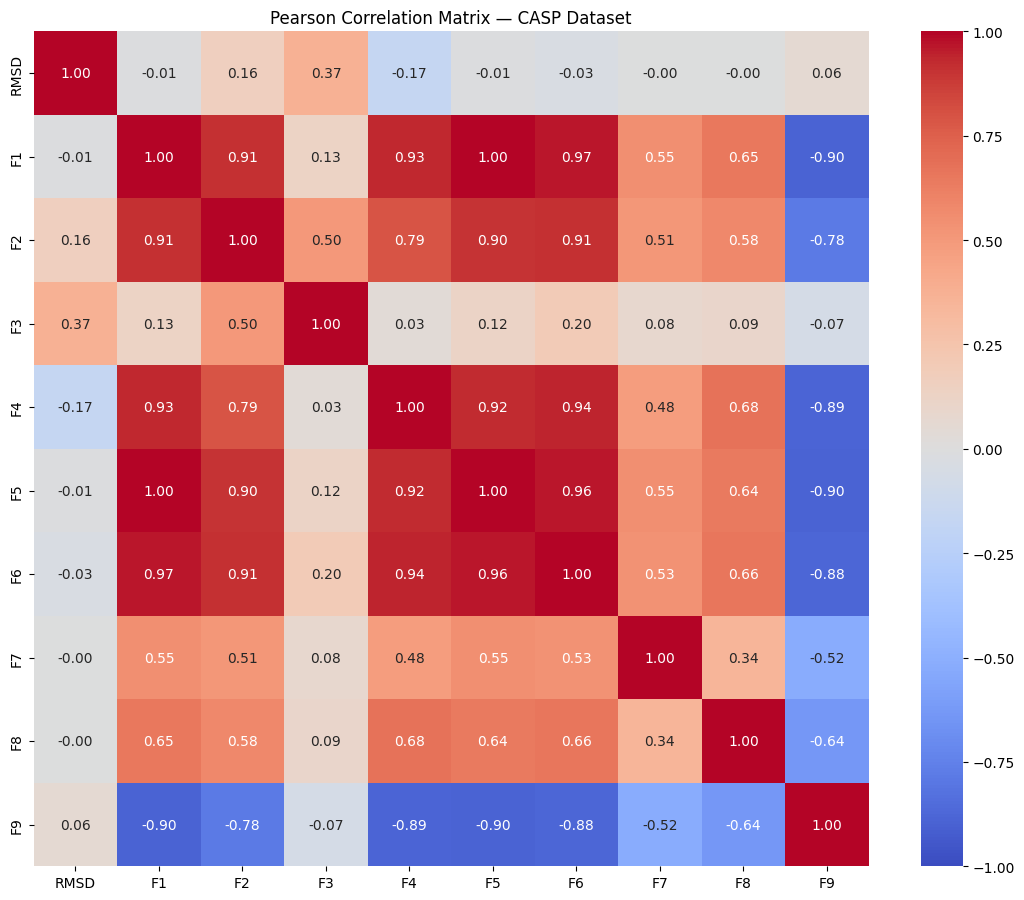

In [10]:
# Calculate the Pearson correlation matrix
corr_matrix = df.corr(method="pearson")

# Create the correlation heatmap
plt.figure(figsize=(11, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Pearson Correlation Matrix — CASP Dataset")
plt.tight_layout()
plt.show()

### Pearson Correlation Analysis — Findings

The correlation matrix reveals two important characteristics
of the CASP dataset.

**1. Relationships with RMSD**

F3 exhibits the strongest positive linear association with
RMSD (r = 0.37).

F4 (r = -0.17) and F2 (r = 0.16) show weaker linear
relationships.

Most remaining descriptors have negligible individual
Pearson correlations with RMSD.

This does not imply that these features lack predictive
value, because Pearson correlation captures only linear
relationships.

**2. Multicollinearity among predictors**

Several physicochemical descriptors are strongly correlated:

- F1 and F5: r approximately 1.00
- F1 and F6: r = 0.97
- F5 and F6: r = 0.96
- F4 and F6: r = 0.94
- F1 and F9: r = -0.90

These relationships suggest substantial multicollinearity.

**Machine Learning Implications**

- Linear regression will provide an interpretable benchmark,
  but correlated predictors may complicate coefficient
  interpretation.
- Nonlinear models such as Random Forest and
  HistGradientBoosting will be evaluated.
- Feature importance and predictive performance will be
  assessed before considering feature removal.
- No predictors will be removed solely based on the
  correlation matrix.


In [11]:
# Rank predictor correlations with RMSD
rmsd_correlations = (
    df.corr(method="pearson")["RMSD"]
    .drop("RMSD")
    .sort_values(key=abs, ascending=False)
)

print("Predictor correlations with RMSD:")
display(rmsd_correlations)

Predictor correlations with RMSD:


F3    0.373389
F4   -0.169258
F2    0.158351
F9    0.061939
F6   -0.034420
F1   -0.013087
F5   -0.011956
F7   -0.003116
F8   -0.000032
Name: RMSD, dtype: float64

### Correlation Analysis — Conclusions

F3 shows the strongest individual linear association with RMSD
(r = 0.3734), followed by F4 (r = -0.1693) and F2 (r = 0.1584).

The remaining predictors exhibit weak or negligible linear
correlations with the target.

However, low Pearson correlation does not exclude nonlinear
predictive relationships or interactions between variables.

Strong correlations among several predictors also indicate
substantial multicollinearity.

These findings motivate comparing linear regression with
nonlinear ensemble models.

All nine predictors will initially be retained for modeling.


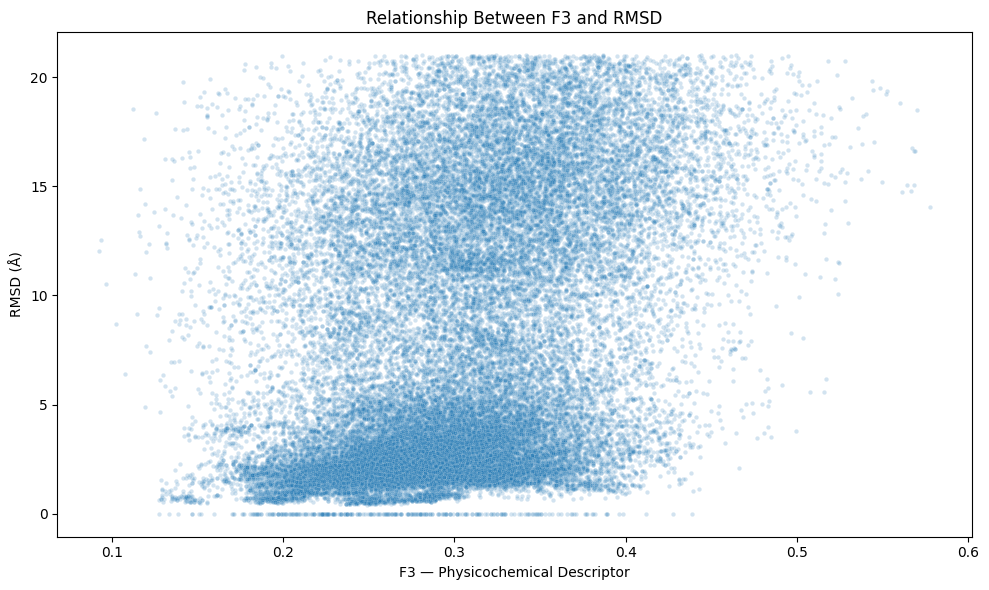

In [12]:
# Visualize the relationship between F3 and RMSD
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="F3",
    y="RMSD",
    alpha=0.2,
    s=10
)

plt.title("Relationship Between F3 and RMSD")
plt.xlabel("F3 — Physicochemical Descriptor")
plt.ylabel("RMSD (Å)")

plt.tight_layout()
plt.show()

### F3–RMSD Relationship — Findings

The scatter plot reveals a complex relationship between F3
and RMSD.

F3 exhibits a moderate positive Pearson correlation with RMSD
(r = 0.3734), but the observations show substantial variability.

Two broad concentrations of RMSD values are visible,
consistent with the previously observed bimodal target
distribution.

At similar F3 values, RMSD can vary considerably,
indicating that F3 alone is insufficient for accurate
prediction of protein structural deviation.

The relationship does not appear to follow a simple
linear pattern.

**Machine Learning Implications**

- Linear Regression will provide a useful baseline.
- Nonlinear models may capture relationships not represented
  by a simple linear model.
- Interactions among physicochemical descriptors may improve
  predictive performance.
- The relative performance of linear and nonlinear models
  must be established experimentally.


## Hypothesis Testing — F3 and RMSD

### Research Question

Is there a statistically significant linear association between
the physicochemical descriptor F3 and RMSD?

### Hypotheses

- **Null hypothesis (H0):** There is no linear correlation
  between F3 and RMSD in the underlying population (ρ = 0).

- **Alternative hypothesis (H1):** There is a linear
  correlation between F3 and RMSD (ρ ≠ 0).

### Statistical Method

Pearson's correlation test is used to evaluate the strength
and statistical significance of the linear association.

The significance level is set at α = 0.05.

If p < 0.05, the null hypothesis will be rejected.
Otherwise, there is insufficient evidence to reject it.

The analysis is exploratory, and statistical significance
does not imply causation.


In [13]:
from scipy.stats import pearsonr

# Pearson correlation and hypothesis test
r_value, p_value = pearsonr(df["F3"], df["RMSD"])

print("Pearson Correlation Test — F3 vs RMSD")
print(f"Correlation coefficient (r): {r_value:.4f}")
print(f"P-value: {p_value:.3e}")

alpha = 0.05

if p_value < alpha:
    print("Result: Reject the null hypothesis (H0).")
else:
    print("Result: Fail to reject the null hypothesis (H0).")

Pearson Correlation Test — F3 vs RMSD
Correlation coefficient (r): 0.3734
P-value: 0.000e+00
Result: Reject the null hypothesis (H0).


### Hypothesis Test Results and Interpretation

The Pearson correlation test was performed to investigate
the linear association between the physicochemical descriptor
F3 and RMSD.

**Results:**

- Pearson correlation coefficient: r = 0.3734
- P-value: extremely small (displayed as 0.000e+00)
- Significance level: α = 0.05
- Decision: Reject the null hypothesis (H0)

The results indicate a statistically significant positive
linear association between F3 and RMSD under the assumptions
of the Pearson correlation test.

The correlation coefficient of 0.3734 indicates a moderate
positive association. Higher F3 values tend to be associated
with higher RMSD values, although considerable variability
remains.

The squared correlation coefficient (r² ≈ 0.139) indicates
that a simple linear model using F3 alone would explain
approximately 13.9% of the observed RMSD variance.

**Limitations:**

Statistical significance does not establish causation.
Furthermore, the CASP dataset does not provide protein
identifiers, so the independence of observations cannot be
fully verified. Related protein models may be represented
in the dataset.

Therefore, the p-value should be interpreted cautiously,
and the findings are considered exploratory.

**Conclusion:**

The null hypothesis of zero linear correlation is rejected
under the test assumptions. F3 is associated with RMSD,
but the moderate correlation suggests that additional
descriptors and potentially nonlinear relationships should
be investigated through machine learning.


## Section 5 — EDA Summary and Implications for Machine Learning

The exploratory data analysis identified several important characteristics of the cleaned CASP dataset, consisting of 44,019 observations and nine physicochemical predictors (F1–F9), with RMSD as the target variable.

### 5.1 Key Findings from Descriptive Statistics

The RMSD target exhibits an apparently bimodal distribution, with concentrations of observations at relatively low and high structural deviations.

Descriptive statistical analysis revealed:

- **Mean RMSD:** 7.796 Å
- **Median RMSD:** 5.087 Å
- **Standard deviation:** 6.138 Å
- **Variance:** 37.673 Å²
- **Skewness:** 0.553

The mean is higher than the median, consistent with a moderately right-skewed distribution. The relatively large standard deviation indicates substantial variability in structural deviation across observations.

The empirical probability of RMSD below 5 Å was **49.6%**, indicating that approximately half of the observations in the cleaned dataset fall below this threshold.

Most physicochemical descriptors also exhibit right-skewed distributions. F7 contains a small number of extreme upper-tail observations, which were retained because there was insufficient evidence to classify them as erroneous.

### 5.2 Correlation Analysis and Hypothesis Testing

Pearson correlation analysis revealed substantial multicollinearity among several predictors, particularly F1, F5, and F6.

Among the individual descriptors, F3 demonstrated the strongest linear association with RMSD:

- **Pearson correlation coefficient:** r = 0.3734
- **P-value:** Extremely small (displayed as 0.000e+00)
- **Significance level:** α = 0.05

The hypothesis test evaluated whether a linear association exists between F3 and RMSD.

- **Null hypothesis (H0):** The population correlation between F3 and RMSD is zero.
- **Alternative hypothesis (H1):** The population correlation between F3 and RMSD is nonzero.

The null hypothesis was rejected under the assumptions of the Pearson correlation test.

The positive correlation indicates that higher F3 values tend to be associated with higher RMSD values. However, the moderate correlation coefficient suggests that considerable variability remains unexplained.

The squared correlation coefficient (r² ≈ 0.139) indicates that a simple linear regression using F3 alone would explain approximately 13.9% of the observed RMSD variance.

These findings suggest that RMSD prediction may benefit from considering multiple physicochemical descriptors and nonlinear relationships.

### 5.3 Statistical and Dataset Limitations

Several limitations should be considered when interpreting the results:

- Statistical significance does not establish causation.
- The very large sample size can produce extremely small p-values even for moderate associations.
- The dataset does not contain protein identifiers, preventing verification of independence between potentially related protein models.
- The Pearson correlation test assumes independent observations; therefore, its p-value should be interpreted cautiously.
- The apparent bimodality of RMSD is based on visual inspection rather than a formal test of multimodality.
- Extreme predictor values were retained because their validity could not be determined from the available information.

Consequently, the statistical findings are considered exploratory and should not be interpreted as establishing causal relationships or generalization to entirely unseen proteins.

### 5.4 Implications for Model Development

The EDA findings inform the following machine learning strategy:

- Establish baseline performance using `DummyRegressor` and `LinearRegression`.
- Compare nonlinear regression algorithms, including `RandomForestRegressor` and `HistGradientBoostingRegressor`.
- Apply feature scaling within pipelines where appropriate.
- Retain all nine predictors initially and evaluate their contribution during modeling.
- Evaluate predictive performance using MAE, RMSE, and R².
- Use group-aware splitting and cross-validation to prevent identical predictor combinations from appearing across training and validation or test partitions.
- Investigate prediction errors across different RMSD ranges.
- Assess potential overfitting by comparing training and cross-validation performance.
- Reserve the held-out test dataset for final model evaluation.

### 5.5 Overall Conclusion

The exploratory analysis demonstrates substantial variability in protein structural deviation and identifies statistically significant but moderate linear associations between individual physicochemical descriptors and RMSD.

The observed multicollinearity, heterogeneous distributions, and limited explanatory power of individual predictors motivate the evaluation of multivariable and nonlinear regression models.

The descriptive statistical analysis, empirical probability calculations, correlation analysis, and hypothesis testing provide a quantitative foundation for the subsequent machine learning workflow.